# Buổi B2: Đo sai số, MAE, RMSE, R² và cách chọn thước đo

**Hiện trường.** Chị Hạnh (điều dưỡng trưởng) nhờ ba đồng nghiệp đánh giá **cùng một mô hình** đoán điểm tiến triển bệnh. Ba người báo ba con số khác nhau:

- Anh A: *"Sai trung bình 52 điểm."*
- Chị B: *"Sai 64 điểm."*
- Anh C: *"R² là 0,23."*

Chị Hạnh hỏi: *"Ai nói đúng? Tôi nên báo cáo con số nào cho ban giám đốc?"* Cả ba đều đúng. Mỗi con số là **một cách đo khác nhau** của cùng một sai lệch, và chọn thước đo nào là một **quyết định**.

**Câu hỏi của buổi này:** *ba con số đó đến từ đâu, mỗi con số nhạy với điều gì, và khi nào dùng con số nào?*

**Mindset của người làm dữ liệu:** thước đo không phải sự thật khách quan; nó là *góc nhìn*. Chọn góc nhìn sao cho khớp với cái giá của sai lầm ngoài đời.

**Lưu ý:** dữ liệu bệnh nhân là dữ liệu mẫu của scikit-learn để học, không dùng để chẩn đoán. Buổi này dùng lại cú pháp từ A1 đến B1 mà không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Sai lệch từng bệnh nhân: nhìn trước khi gộp thành một con số |
| Chặng 2 | MAE: sai lệch trung bình, con số dễ hiểu nhất |
| Chặng 3 | MSE và RMSE: vì sao bình phương, và nó nhạy với điều gì |
| Chặng 4 | R²: so với mốc lười, và cái bẫy khi thêm cột rác |
| Chặng 5 | Chọn thước đo theo cái giá của sai lầm |

## Chặng 1: Sai lệch từng bệnh nhân, nhìn trước khi gộp thành một con số

**Câu hỏi:** mô hình sai ở từng người như thế nào, trước khi ta gộp thành một con số?

Ta dùng lại mô hình của B1: đoán điểm tiến triển từ BMI, chia tập học và tập thi như thường lệ.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
patients = load_diabetes(as_frame=True, scaled=False).frame
X, y = patients[["bmi"]], patients["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
residuals = y_test - pred
print("Test patients:", len(y_test), "| first five residuals:", residuals.head().round(0).tolist())

Test patients: 89 | first five residuals: [73.0, -119.0, 54.0, 26.0, -21.0]


**Giải thích từng dòng**

- `from ... import ... (ba dòng)`: (đã học) đủ bộ đồ nghề: mở dữ liệu, máy hồi quy, chia sổ.
- `X, y = patients[["bmi"]], patients["target"]`: (đã học ở B1) X là bảng một cột, y là một cột.
- `model = LinearRegression().fit(X_train, y_train)`: (đã học) học đường thẳng trên tập học.
- `pred = model.predict(X_test)`: (đã học) đoán cho tập thi.
- `residuals = y_test - pred`: **phần dư** (residual) = đáp án thật trừ đáp án đoán, **có dấu**. Dương nghĩa là máy đoán **thấp hơn** thực tế; âm nghĩa là máy đoán **cao hơn**. Đây là nguyên liệu thô của mọi thước đo sai số.
- `residuals.head().round(0).tolist()`: (đã học) lấy 5 phần dư đầu, làm tròn, đổi thành danh sách cho gọn.

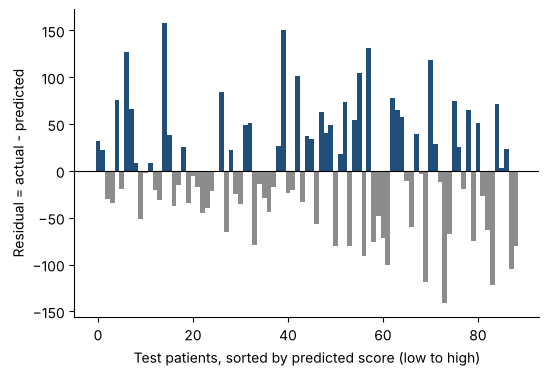

In [3]:
order = np.argsort(pred)
plt.bar(range(len(order)), residuals.to_numpy()[order], color=np.where(residuals.to_numpy()[order] > 0, BLUE, GRAY), width=1.0)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Test patients, sorted by predicted score (low to high)")
plt.ylabel("Residual = actual - predicted")
plt.show()

**Giải thích từng dòng**

- `order = np.argsort(pred)`: (đã học `argsort` ở A2) thứ tự xếp bệnh nhân theo điểm **đoán** từ thấp đến cao, để hình có trật tự thay vì lộn xộn.
- `plt.bar(range(len(order)), residuals.to_numpy()[order], color=..., width=1.0)`: (đã học `bar`) mỗi cột là một bệnh nhân. `.to_numpy()` đổi cột pandas thành mảng numpy để xếp lại theo `[order]`. `np.where(điều_kiện, màu_nếu_đúng, màu_nếu_sai)` tô xanh phần dư dương (máy đoán thấp), xám phần dư âm. `width=1.0` làm các cột chạm sát nhau.

**Cách đọc**

- **Con số:** 89 bệnh nhân thi; phần dư lớn nhất khoảng +158 (máy đoán thấp hơn thật 158 điểm) và nhỏ nhất khoảng −141 (máy đoán cao hơn thật 141 điểm).
- **Bức tranh:** nhìn từ trái sang phải, bên **trái** phần lớn là cột xanh (phần dư dương: máy đoán **thấp hơn** thực tế), bên **phải** phần lớn là cột xám (máy đoán **cao hơn** thực tế). Máy đoán "co về giữa": người nhẹ thì bị đoán nhẹ hơn thật, người nặng thì bị đoán nặng hơn thật. Đó là dấu hiệu một cột đề (BMI) chưa đủ thông tin. Ngoài ra độ cao các cột **lớn**: nhiều bệnh nhân sai hàng chục điểm, có người sai tới 150.
- **Vấn đề:** 89 cột thì không báo cáo được cho ban giám đốc. Cần *gộp thành một con số*. Có hai cách gộp phổ biến, mỗi cách trả lời một câu hỏi khác nhau.

**Mang về chặng 1:** mọi thước đo sai số đều xuất phát từ **phần dư** = thật − đoán. Dấu của phần dư cho biết máy đoán thấp hay cao; độ lớn cho biết sai nhiều hay ít.

## Chặng 2: MAE, sai lệch trung bình, con số dễ hiểu nhất

**Câu hỏi:** cách gộp đơn giản nhất là gì?

Bỏ dấu (lấy trị tuyệt đối, để âm và dương không triệt tiêu nhau) rồi lấy **trung bình**. Đó là **MAE** (Mean Absolute Error, sai số tuyệt đối trung bình).

In [4]:
from sklearn.metrics import mean_absolute_error
mae_by_hand = residuals.abs().mean()
mae_sklearn = mean_absolute_error(y_test, pred)
print("MAE by hand:", round(mae_by_hand, 2), "| by sklearn:", round(mae_sklearn, 2))
print("Sum of residuals (signs cancel!):", round(residuals.sum(), 1))

MAE by hand: 52.26 | by sklearn: 52.26
Sum of residuals (signs cancel!): 57.5


**Giải thích từng dòng**

- `mae_by_hand = residuals.abs().mean()`: (đã học ở A1) bỏ dấu, rồi lấy trung bình.
- `mae_sklearn = mean_absolute_error(y_test, pred)`: (đã học ở B1) cùng kết quả bằng hàm có sẵn.
- `residuals.sum()`: cộng thẳng các phần dư **có dấu**. Để thấy vì sao phải bỏ dấu: dương và âm triệt tiêu nhau.

**Cách đọc**

- **Con số:** MAE khoảng **52,3 điểm**. Cộng thẳng các phần dư chỉ ra khoảng **57,5**, nhỏ vô lý so với 89 người sai cả chục điểm, vì cộng dương trừ âm rồi triệt tiêu. Đó là lý do phải bỏ dấu trước.
- **Bức tranh:** MAE nói: *"Một bệnh nhân bất kỳ, máy đoán lệch trung bình 52 điểm."* Đơn vị **chính là đơn vị của đáp án** (điểm), nên người không chuyên cũng hiểu.
- **Tính chất quan trọng:** MAE đối xử mọi sai lệch **công bằng như nhau**: sai 100 là gấp đôi sai 50, không hơn.
- **Mốc so sánh:** MAE đứng một mình ít nói gì. Phải so với **mốc lười** (đoán trung bình). Ở B1 ta đã làm điều này; mốc lười ở bài này sai khoảng 64 điểm.

## Chặng 3: MSE và RMSE, vì sao bình phương, và nó nhạy với điều gì

**Câu hỏi:** chị B báo 64 thay vì 52. Cách tính của chị khác ở đâu?

Chị B **bình phương** từng phần dư rồi lấy trung bình (MSE, Mean Squared Error), sau đó **lấy căn bậc hai** để quay về đơn vị điểm (RMSE, Root Mean Squared Error). Hãy xem việc bình phương làm gì, bằng hình: sai lệch bình phương chính là **diện tích hình vuông** có cạnh bằng sai lệch.

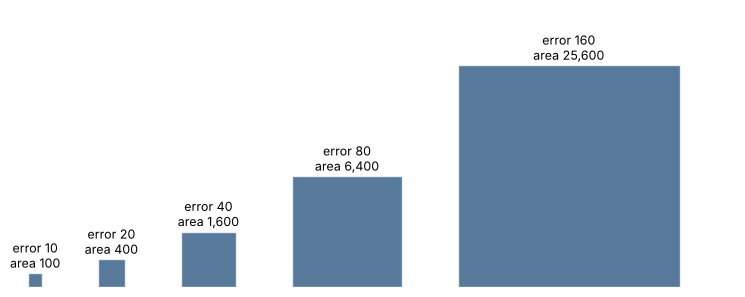

In [5]:
# Decorative diagram: just run it, no need to read the code line by line.
from matplotlib.patches import Rectangle
sample = [10, 20, 40, 80, 160]
fig, ax = plt.subplots(figsize=(10, 3.6))
left = 0
for e in sample:
    ax.add_patch(Rectangle((left, 0), e, e, fc=BLUE, alpha=0.75, ec="white"))
    ax.text(left + e / 2, e + 4, f"error {e}\narea {e*e:,}", ha="center", fontsize=9)
    left += e + 40
ax.set_xlim(0, left); ax.set_ylim(0, 200); ax.set_aspect("equal"); ax.axis("off")
plt.show()

**Cách đọc**

- **Con số:** sai 10 có diện tích 100; sai 20 (gấp đôi) có diện tích 400 (gấp **4**); sai 160 (gấp 16 lần sai 10) có diện tích 25 600 (gấp **256** lần).
- **Bức tranh:** hình vuông của sai lệch lớn **phình ra rất nhanh**. Khi lấy trung bình các diện tích, một hình vuông khổng lồ lấn át đám hình vuông nhỏ. Nghĩa là **RMSE phạt nặng sai lệch lớn**, còn MAE thì không.
- **Hệ quả:** hai mô hình cùng MAE có thể khác RMSE rất xa, tùy sai lệch dồn vào một chỗ hay rải đều. Kiểm chứng bằng một thí nghiệm có số liệu sạch:

In [6]:
from sklearn.metrics import mean_squared_error
truth = np.zeros(10)
model_even = np.full(10, 40.0)
model_spiky = np.array([10.0] * 9 + [310.0])
for name, p in [("even errors", model_even), ("one huge miss", model_spiky)]:
    print(f"{name:14s} MAE = {mean_absolute_error(truth, p):5.1f} | RMSE = {np.sqrt(mean_squared_error(truth, p)):5.1f}")

even errors    MAE =  40.0 | RMSE =  40.0
one huge miss  MAE =  40.0 | RMSE =  98.5


**Giải thích từng dòng**

- `from sklearn.metrics import mean_squared_error`: lấy hàm tính **MSE** (trung bình bình phương sai lệch). Muốn RMSE thì lấy căn bậc hai.
- `truth = np.zeros(10)`: đáp án thật giả định bằng 0 cho cả 10 ca, để sai lệch chính là độ lớn của số đoán: dễ đọc.
- `model_even = np.full(10, 40.0)`: `np.full(số_lượng, giá_trị)` tạo mảng 10 số, mỗi số là 40: mô hình sai **đều 40** ở mọi ca.
- `model_spiky = np.array([10.0] * 9 + [310.0])`: mô hình sai **10** ở 9 ca và **310** ở 1 ca. `[10.0] * 9` là lặp danh sách 9 lần; `+` nối hai danh sách.
- `np.sqrt(mean_squared_error(truth, p))`: căn bậc hai của MSE = **RMSE**. `np.sqrt` (square root) là hàm căn bậc hai.
- `f"{name:14s} MAE = {...:5.1f}"`: (đã học `f-string` và `:.0f` ở A5) `:14s` căn chữ rộng 14 ký tự cho thẳng hàng; `:5.1f` số rộng 5 ký tự, 1 chữ số thập phân.

**Cách đọc**

- **Con số:** cả hai mô hình có **MAE = 40**. Nhưng RMSE: mô hình sai đều là **40**, mô hình có một lần sai khổng lồ là **khoảng 98**.
- **Bức tranh:** MAE nhìn hai mô hình **như nhau**, RMSE nhìn thấy ngay mô hình thứ hai *có một ca sai kinh khủng*. Nếu ngoài đời một ca sai 310 điểm là thảm họa (bỏ sót một bệnh nhân nguy kịch) thì RMSE mới là con số **cảnh báo đúng**.
- **Quan hệ luôn đúng:** RMSE **luôn lớn hơn hoặc bằng** MAE. Chúng bằng nhau khi mọi sai lệch đều bằng nhau. Chênh lệch càng lớn thì sai lệch càng **dồn vào ít ca**. Với bệnh nhân thật, MAE 52 và RMSE 64: chênh vừa phải, nghĩa là sai lệch **không quá dồn cục**.
- **Vì sao dân thống kê thích bình phương?** Một lý do toán học (dễ tìm đường tối ưu, như bình phương tối thiểu ở B1). Một lý do thực tế: nó *phạt sai lệch lớn*.

**Mang về chặng 3:** RMSE = căn của trung bình bình phương sai lệch. Cùng đơn vị với đáp án như MAE, nhưng **phạt nặng ca sai lớn**. So hai số: RMSE xa MAE nghĩa là có vài ca sai rất nặng.

## Chặng 4: R², so với mốc lười, và cái bẫy khi thêm cột rác

**Câu hỏi:** anh C báo R² = 0,23. Con số này có đơn vị không, và nó so với cái gì?

MAE và RMSE có đơn vị (điểm). R² thì **không có đơn vị**: nó so sánh mô hình với **mốc lười** (đoán trung bình). Công thức: **R² = 1 − (tổng bình phương sai lệch của mô hình) / (tổng bình phương sai lệch của mốc lười)**.

In [7]:
sse_model = (residuals ** 2).sum()
sse_lazy = ((y_test - y_test.mean()) ** 2).sum()
r2_by_hand = 1 - sse_model / sse_lazy
from sklearn.metrics import r2_score
print("SSE model:", round(sse_model), "| SSE lazy:", round(sse_lazy))
print("R2 by hand:", round(r2_by_hand, 3), "| by sklearn:", round(r2_score(y_test, pred), 3))

SSE model: 361503 | SSE lazy: 471536
R2 by hand: 0.233 | by sklearn: 0.233


**Giải thích từng dòng**

- `sse_model = (residuals ** 2).sum()`: tổng bình phương sai lệch của mô hình (SSE, Sum of Squared Errors), giống thước đo `fit` ở B1.
- `sse_lazy = ((y_test - y_test.mean()) ** 2).sum()`: tổng bình phương sai lệch của **mốc lười**: cứ đoán **trung bình của chính tập thi** (`y_test.mean()`) cho mọi bệnh nhân. Định nghĩa chuẩn của R² dùng trung bình của tập đang chấm, nên ta làm theo để khớp với `r2_score`.
- `r2_by_hand = 1 - sse_model / sse_lazy`: một trừ tỉ số hai tổng. Mô hình tốt thì tử số nhỏ, tỉ số gần 0, R² gần 1.
- `from sklearn.metrics import r2_score`: hàm R² có sẵn; thứ tự `(thật, đoán)`. Kết quả trùng với `model.score` ở B1 (vì `.score` của hồi quy chính là R²).

**Cách đọc**

- **Con số:** R² khoảng **0,23**. Tức SSE của mô hình bằng khoảng **77%** SSE của mốc lười (tử số và mẫu số cùng cỡ vài trăm nghìn, tỉ số khoảng 0,77). Mô hình **cắt bớt khoảng 23%** tổng bình phương sai lệch so với việc đoán trung bình.
- **Bức tranh:** hãy hình dung hai chồng hình vuông (như hình ở chặng 3): chồng của mốc lười và chồng của mô hình. R² là *tỉ lệ chồng hình vuông đã được dọn bớt*. Dọn hết là 1; chẳng dọn gì là 0; dọn ít hơn mốc lười, làm bừa thêm, là **số âm**.
- **R² không nói được:** nó không cho biết sai bao nhiêu **điểm**. Anh C chỉ biết "khá hơn mốc lười", chưa biết "sai bao nhiêu điểm". Vì vậy báo cáo luôn nên có **cả MAE (đơn vị thật) lẫn R² (so với mốc)**.

Bây giờ là cái bẫy. Điều gì xảy ra nếu ta **thêm các cột rác**, toàn số ngẫu nhiên không liên quan gì đến bệnh?

In [8]:
rng = np.random.default_rng(0)
rows = []
for n_junk in [0, 10, 30, 60, 100]:
    junk = pd.DataFrame(rng.normal(size=(len(X), n_junk)), columns=[f"junk_{i}" for i in range(n_junk)], index=X.index)
    Xj = pd.concat([X, junk], axis=1)
    a, b, c, d = train_test_split(Xj, y, test_size=0.2, random_state=42)
    m = LinearRegression().fit(a, c)
    rows.append({"junk columns": n_junk, "train R2": m.score(a, c), "test R2": m.score(b, d)})
junk_table = pd.DataFrame(rows).round(3)
junk_table

,junk columns,train R2,test R2
0,0,0.366,0.233
1,10,0.387,0.255
2,30,0.432,0.224
3,60,0.437,0.009
4,100,0.566,-0.183


**Giải thích từng dòng**

- `rng = np.random.default_rng(0)`: (đã học ở A2) bộ phát số ngẫu nhiên với hạt giống 0.
- `for n_junk in [0, 10, 30, 60, 100]:`: (đã học vòng lặp) thử thêm 0, 10, 30, 60, 100 cột rác.
- `junk = pd.DataFrame(rng.normal(size=(len(X), n_junk)), ...)`: **mới:** `rng.normal(size=(số_dòng, số_cột))` sinh bảng số **ngẫu nhiên theo hình chuông** (trung bình 0, phân tán 1). Đó chính là cột rác: không liên quan gì đến bệnh nhân. `columns=[...]` đặt tên cột bằng danh sách; `index=X.index` ép bảng rác dùng **cùng số thứ tự dòng** với `X` để ghép đúng.
- `Xj = pd.concat([X, junk], axis=1)`: (đã học `concat` ở A2, nhưng ở dạng ghép dòng) `axis=1` ghép **theo chiều cột**: đặt bảng rác **cạnh** bảng BMI.
- `a, b, c, d = train_test_split(Xj, y, ...)`: chia như cũ (cùng hạt giống nên cùng bệnh nhân thi). Dùng các tên ngắn `a, b, c, d` cho bốn phần để gọn trong vòng lặp.
- `rows.append({"junk columns": ..., "train R2": ..., "test R2": ...})`: (đã học `append`) mỗi vòng ghi một dòng kết quả.

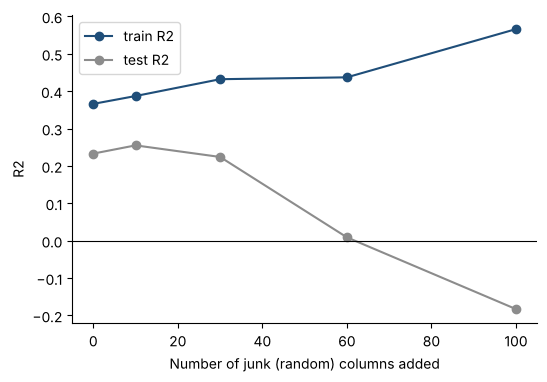

In [9]:
plt.plot(junk_table["junk columns"], junk_table["train R2"], "o-", color=BLUE, label="train R2")
plt.plot(junk_table["junk columns"], junk_table["test R2"], "o-", color=GRAY, label="test R2")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Number of junk (random) columns added"); plt.ylabel("R2")
plt.legend(); plt.show()

**Giải thích từng dòng**

- `plt.plot(..., "o-", color=BLUE, label="train R2")`: (đã học) đường R² trên tập học.
- `plt.plot(..., color=GRAY, label="test R2")`: đường R² trên tập thi.

**Cách đọc**

- **Con số:** thêm càng nhiều cột rác, R² **trên tập học tăng** (từ 0,37 lên 0,57 khi có 100 cột rác), còn R² **trên tập thi giảm** (từ 0,23, xuống 0,01 ở 60 cột, và **âm** −0,18 ở 100 cột, tệ hơn cả mốc lười). Ở mức 10 cột rác điểm thi còn nhích nhẹ lên: đó là may rủi của một lần chia, nhớ lại A4.
- **Bức tranh:** hai đường **xòe ra** như cái kéo: đường xanh đi lên, đường xám đi xuống. Cột rác không chứa thông tin thật, nhưng máy vẫn tìm cách **dùng** chúng để khớp ngẫu nhiên với tập học. Đó là **quá khớp** (đã gặp ở A4), ở dạng "học vẹt bằng cột rác".
- **Hệ quả cho việc đọc R²:** *R² trên tập học luôn tăng khi thêm cột*, dù cột đó vô dụng. Vì vậy **chỉ tin R² trên tập thi**. Một mô hình hoành tráng với R² train 0,9 chưa chắc có gì: hãy xem R² test.

**Mang về chặng 4:** R² = 1 − SSE mô hình / SSE mốc lười; không có đơn vị; 1 là hoàn hảo, 0 là bằng mốc lười, **âm** là tệ hơn mốc lười. Chỉ tin R² trên tập thi vì R² train luôn tăng khi thêm cột.

## Chặng 5: Chọn thước đo theo cái giá của sai lầm

**Câu hỏi:** chị Hạnh nên báo cáo con số nào?

Hãy gom cả ba con số của ba đồng nghiệp lại và nhìn cùng với một câu hỏi quyết định: *"Chọn 10 bệnh nhân cần theo dõi sát, ai chọn đúng hơn?"*

In [10]:
lazy_pred = np.full(len(y_test), y_train.mean())
summary = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, pred), mean_absolute_error(y_test, lazy_pred)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, pred)), np.sqrt(mean_squared_error(y_test, lazy_pred))],
    "R2": [r2_score(y_test, pred), r2_score(y_test, lazy_pred)],
}, index=["BMI model", "lazy (mean)"]).round(2)
summary

,MAE,RMSE,R2
BMI model,52.26,63.73,0.23
lazy (mean),64.01,73.22,-0.01


**Giải thích từng dòng**

- `lazy_pred = np.full(len(y_test), y_train.mean())`: (đã học `np.full`) mốc lười: số trung bình của tập học, lặp cho mọi người trong tập thi.
- `summary = pd.DataFrame({"MAE": [...], "RMSE": [...], "R2": [...]}, index=[...])`: bảng 2 dòng (mô hình, mốc lười) × 3 cột (ba thước đo). `index=[...]` đặt **tên dòng**.

**Cách đọc**

- **Con số:** mô hình có MAE 52,3, RMSE 63,7, R² 0,23; mốc lười có MAE 64,0, RMSE 73,2, R² −0,01. (R² của mốc lười hơi âm vì ở đây nó đoán bằng trung bình tập *học*, còn định nghĩa R² dùng trung bình tập *thi*.)
- **Bức tranh:** mô hình **thắng mốc lười ở cả ba thước đo**, nhưng mức thắng nhìn **khác nhau**: MAE giảm khoảng 18%, RMSE giảm khoảng 13%, R² nhảy từ 0 lên 0,23. Mỗi thước đo kể một phần câu chuyện, không cái nào sai.

**Bảng chọn thước đo, trả lời theo câu hỏi của người ra quyết định**

| Nếu quyết định cần... | Dùng | Vì sao |
|---|---|---|
| Biết **sai bao nhiêu đơn vị** trung bình, mọi sai lệch đáng như nhau | **MAE** | Dễ hiểu nhất, không bị ca sai lớn kéo lệch |
| **Tránh các sai lầm lớn**, một ca sai nặng là thảm họa | **RMSE** | Bình phương phạt nặng ca sai lớn |
| **So sánh mô hình với mốc lười**, hoặc so giữa các bài toán có đơn vị khác nhau | **R²** (trên tập thi) | Không có đơn vị, mốc là 0 |
| **Chọn ra top k người** (như chọn 10 bệnh nhân theo dõi) | **Thước đo theo quyết định** (như điểm trung bình của k người chọn, ở A3 đến A5) | Thước đo chung không biết ta chỉ quan tâm k người đầu bảng |

**Phán quyết cho chị Hạnh:** báo cáo **cả hai**: *"Mô hình đoán sai trung bình khoảng 52 điểm (MAE) và có vài ca sai tới hơn 140; đoán tốt hơn việc đoán trung bình khoảng 18%; giải thích được khoảng 23% dao động (R²)."* Ban giám đốc có đơn vị thật để hình dung và có mốc để so.

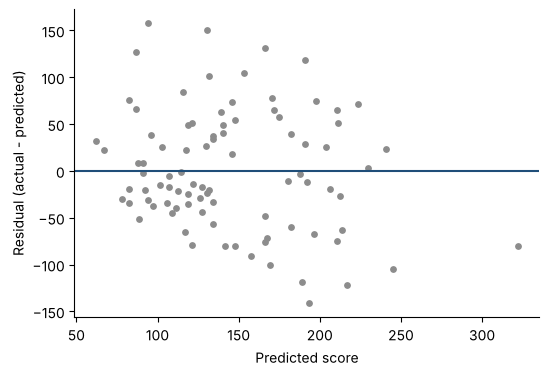

In [11]:
residual_plot_x = pred
plt.scatter(residual_plot_x, residuals, color=GRAY, s=15)
plt.axhline(0, color=BLUE)
plt.xlabel("Predicted score"); plt.ylabel("Residual (actual - predicted)")
plt.show()

**Giải thích từng dòng**

- `plt.scatter(residual_plot_x, residuals, color=GRAY, s=15)`: **biểu đồ phần dư**: trục ngang là điểm **đoán**, trục dọc là phần dư. Đây là cách **nhìn** sai số thay vì chỉ đọc con số.
- `plt.axhline(0, color=BLUE)`: vạch 0: chỗ phần dư bằng 0 (đoán trúng).

**Cách đọc**

- **Con số:** chia các bệnh nhân thi thành ba nhóm theo điểm đoán: nhóm đoán dưới 130 (39 người) có sai lệch trung bình khoảng **39 điểm**; nhóm 130 đến 170 (23 người) khoảng **67 điểm**; nhóm trên 170 (26 người) khoảng **59 điểm**.
- **Bức tranh:** đám chấm ở bên trái **hẹp hơn** đám chấm ở giữa và bên phải. Và ở nhóm được đoán thấp, các chấm lệch về phía **trên** (phần dư dương, đến +158): có người máy tưởng nhẹ nhưng thực tế nặng hơn nhiều. Con số MAE 52 là *trung bình*, nhưng sai số thật **không đều** giữa các nhóm.
- **Bài học nghề:** biểu đồ phần dư nên là **bước kiểm tra thứ hai** sau con số tổng. Nó cho thấy mô hình sai ở *vùng nào*. Nếu chấm xếp thành đường cong rõ ràng thay vì đám mây quanh 0, thì đường thẳng không đủ và nên thử mô hình khác (B5).

## Phán quyết và bài học nghề

**Phán quyết.** Ba đồng nghiệp đều đúng. Với ban giám đốc, báo cáo **MAE (sai bao nhiêu điểm) + mốc lười + R²** và nêu rõ **ca sai tệ nhất**. Biểu đồ phần dư cho thấy sai lệch không đều giữa các nhóm: nhóm được đoán điểm thấp lệch ít hơn, nhưng có những ca bị đoán thấp hơn thực tế rất nhiều.

**Bài học nghề.**

1. **Mọi thước đo xuất phát từ phần dư** = thật − đoán.
2. **MAE** dễ hiểu, công bằng; **RMSE** phạt ca sai lớn; **R²** so với mốc lười và không có đơn vị.
3. **Luôn đặt cạnh mốc lười.** Một con số đứng một mình không nói gì.
4. **Chỉ tin R² trên tập thi.** R² train tăng khi thêm cột, kể cả cột rác.
5. **Chọn thước đo theo cái giá của sai lầm**, không theo thói quen. Rồi **nhìn biểu đồ phần dư** để biết mô hình yếu ở đâu.

**Một điều thành thật:** không có thước đo nào "đúng nhất". Hai người có thể chọn hai thước đo khác nhau và đưa ra kết luận khác nhau từ cùng một mô hình; điều quan trọng là *nói rõ mình đang dùng thước đo nào và vì sao*.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Mọi thước đo sai số xuất phát từ phần dư = thật − đoán. |
| 2 | MAE: trung bình trị tuyệt đối của phần dư; cùng đơn vị với đáp án; mọi sai lệch tính công bằng. |
| 3 | RMSE: căn của trung bình bình phương; phạt nặng ca sai lớn; luôn lớn hơn hoặc bằng MAE. |
| 4 | R² = 1 − SSE mô hình / SSE mốc lười; không có đơn vị; âm là tệ hơn mốc lười; chỉ tin R² trên tập thi. |
| 5 | Chọn thước đo theo cái giá của sai lầm; thêm biểu đồ phần dư để biết mô hình yếu ở đâu. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Thật trừ đoán, có dấu | phần dư (residual) | `y_test - pred` |
| Sai trung bình, bỏ dấu | MAE | `mean_absolute_error(y, pred)` |
| Căn của sai lệch bình phương trung bình | RMSE | `np.sqrt(mean_squared_error(y, pred))` |
| Trung bình sai lệch bình phương | MSE | `mean_squared_error(y, pred)` |
| Mô hình dọn được bao nhiêu phần hơn mốc lười | R² | `r2_score(y, pred)` |
| Tổng bình phương sai lệch | SSE | `(residuals ** 2).sum()` |
| Cột toàn số ngẫu nhiên | cột rác (nhiễu) | `rng.normal(size=(n, k))` |
| Bảng nhìn sai số theo điểm đoán | biểu đồ phần dư | `plt.scatter(pred, residuals)` |

**Thử thách tự làm**

1. Ở chặng 3, đổi `model_spiky` thành `[20.0] * 8 + [180.0] * 2` (tổng vẫn khớp 10 ca). MAE và RMSE bây giờ chênh nhau bao nhiêu? Mô hình này "dồn cục" nhiều hay ít hơn mô hình một ca sai 310?
2. Dùng cột `s5` (thay cho `bmi`) làm đề cho mô hình một biến. MAE, RMSE, R² của nó so với mô hình BMI thế nào? Biểu đồ phần dư có hình quạt không?
3. Chạy lại thí nghiệm cột rác, nhưng dùng `random_state=7` và `random_state=21` khi chia sổ. Đường R² thi giảm có xảy ra **mọi lần** không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Tính được phần dư và giải thích dấu của nó.
- [ ] Giải thích MAE và RMSE khác nhau ở điểm nào bằng ví dụ.
- [ ] Nói được R² là gì, và khi nào nó âm.
- [ ] Biết vì sao không tin R² trên tập học.
- [ ] Chọn được thước đo hợp lý cho một quyết định cụ thể.
- [ ] Vẽ và đọc được biểu đồ phần dư.

## Phần thưởng (Tip pro): Sai lệch theo phần trăm: MAPE và cái bẫy của số 0


Đôi khi sếp muốn nghe *"sai bao nhiêu phần trăm"*. Thước đo đó là **MAPE** (Mean Absolute Percentage Error): lấy mỗi sai lệch chia cho đáp án thật rồi lấy trung bình. Nó dễ hiểu, nhưng **hỏng khi đáp án thật gần 0** (chia cho số rất nhỏ ra con số khổng lồ) và thiên vị về phía đoán thấp. Nếu đáp án có thể bằng 0 hoặc rất nhỏ, hãy dùng MAE. Chạy ô dưới để thấy MAPE trên bệnh nhân (điểm thấp nhất là 25 nên chưa hỏng): kết quả khoảng **46%**, tức máy lệch trung bình gần một nửa giá trị thật. Nghe đáng sợ hơn nhiều so với "52 điểm", dù là cùng một mô hình. Đó cũng là lý do phải nói rõ mình dùng thước đo nào.

In [12]:
from sklearn.metrics import mean_absolute_percentage_error
print("MAPE:", round(mean_absolute_percentage_error(y_test, pred) * 100, 1), "%")

MAPE: 45.9 %


**Giải thích từng dòng**

- `from sklearn.metrics import mean_absolute_percentage_error`: hàm MAPE có sẵn.
- `mean_absolute_percentage_error(y_test, pred) * 100`: hàm trả về **tỉ lệ** (ví dụ 0,4), nhân 100 mới ra phần trăm.